# Step 5 - Encoding One Video to (100, 20, 4096)

This step applies the per-frame encoding from Step 4 across all 100 frames of a clip and
stacks the results into a `(100, 20, 4096)` tensor, which is one video's portion of the
feature data.

The crops for a frame are passed through VGG in a single batched forward pass rather than
individually, which reduces runtime. A `MAX_FRAMES` setting limits how many frames are
processed for quick testing; the array is always allocated at the full 100 frames, so any
unprocessed frames remain zero.

## Models and helper functions

Consolidated from Steps 2-4, with a batched feature-extraction function.

In [1]:
import cv2, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

VIDEO_PATH  = "../Dataset/videos/test/Accident/000456.mp4"
N_FRAMES    = 100
N_DETECTION = 20
N_OBJECTS   = 19
FEAT_DIM    = 4096
MAX_FRAMES  = 20          # <-- start with 20, then change to 100

# --- detector ---
from torchvision.models.detection import fasterrcnn_resnet50_fpn
try:
    from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
    detector = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
except Exception:
    detector = fasterrcnn_resnet50_fpn(pretrained=True)
detector.eval()

# --- VGG fc7 ---
from torchvision.models import vgg16
try:
    from torchvision.models import VGG16_Weights
    vgg = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
except Exception:
    vgg = vgg16(pretrained=True)
vgg.eval()
vgg_features = vgg.features
vgg_avgpool  = vgg.avgpool
vgg_fc7      = nn.Sequential(*list(vgg.classifier.children())[:5])

KEEP = {1,2,3,4,6,7,8}
SCORE_THRESH = 0.5
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1)
print("models ready.")

models ready.


In [2]:
def detect_boxes(frame_rgb):
    t = torch.from_numpy(frame_rgb).permute(2,0,1).float() / 255.0
    with torch.no_grad():
        out = detector([t])[0]
    kept = []
    for box, label, score in zip(out['boxes'].numpy(), out['labels'].numpy(), out['scores'].numpy()):
        if score >= SCORE_THRESH and int(label) in KEEP:
            kept.append((float(score), box))
    kept.sort(key=lambda z: z[0], reverse=True)
    return [b for _, b in kept[:N_OBJECTS]]

def crop_box(frame_rgb, box):
    h, w, _ = frame_rgb.shape
    x1, y1, x2, y2 = box
    x1 = max(0, int(round(x1))); y1 = max(0, int(round(y1)))
    x2 = min(w, int(round(x2))); y2 = min(h, int(round(y2)))
    if x2 - x1 < 2 or y2 - y1 < 2:
        return None
    return frame_rgb[y1:y2, x1:x2]

def to_features_batch(crops):
    """List of RGB crops -> (len(crops), 4096). One VGG forward pass for all."""
    if not crops:
        return np.zeros((0, FEAT_DIM), dtype=np.float32)
    batch = np.stack([cv2.resize(c, (224,224)) for c in crops]).astype(np.float32) / 255.0
    x = torch.from_numpy(batch).permute(0,3,1,2)      # (N,3,224,224)
    x = (x - IMAGENET_MEAN) / IMAGENET_STD
    with torch.no_grad():
        x = vgg_features(x); x = vgg_avgpool(x); x = torch.flatten(x,1); x = vgg_fc7(x)
    return x.numpy().astype(np.float32)

## Read the frames

In [3]:
cap = cv2.VideoCapture(VIDEO_PATH)
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
cap.release()
print("frames read:", len(frames))

frames read: 100


## Encode every frame and stack into (100, 20, 4096)

In [4]:
video_tensor = np.zeros((N_FRAMES, N_DETECTION, FEAT_DIM), dtype=np.float32)
n = min(MAX_FRAMES, len(frames))

t0 = time.time()
for t in range(n):
    frame = frames[t]
    crops = [frame]                              # slot 0 = whole frame
    for box in detect_boxes(frame):
        crop = crop_box(frame, box)
        if crop is not None:
            crops.append(crop)
        if len(crops) == N_DETECTION:
            break
    feats = to_features_batch(crops)             # (len(crops), 4096)
    video_tensor[t, :feats.shape[0], :] = feats
    if t == 0 or (t+1) % 5 == 0:
        print(f"frame {t+1:3d}/{n}  slots filled: {feats.shape[0]:2d}  "
              f"elapsed: {time.time()-t0:5.1f}s")

print(f"\nDONE {n} frames in {time.time()-t0:.1f}s")
print("video tensor shape:", video_tensor.shape, video_tensor.dtype)

frame   1/20  slots filled:  4  elapsed:   7.2s
frame   5/20  slots filled:  5  elapsed:  32.6s
frame  10/20  slots filled:  4  elapsed:  63.3s
frame  15/20  slots filled:  4  elapsed:  92.7s
frame  20/20  slots filled:  5  elapsed: 121.8s

DONE 20 frames in 121.8s
video tensor shape: (100, 20, 4096) float32


## Inspect slot occupancy over time

The number of filled slots per frame reflects how many objects were detected, comparable to
the sparsity of the author's data.

slots filled per frame (first 20 frames):
[4, 4, 4, 4, 5, 5, 5, 5, 5, 4, 4, 4, 4, 5, 4, 4, 4, 4, 5, 5]

per-slot fill count over processed frames:
[20, 20, 20, 20, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


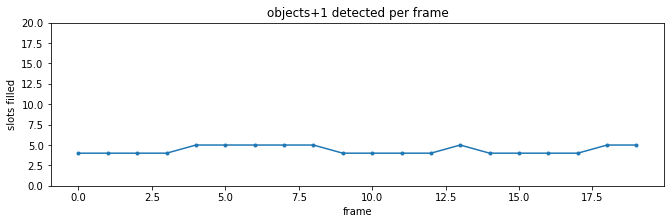

In [5]:
occupied = (np.abs(video_tensor).sum(axis=2) > 0)     # (100, 20) filled?
slots_per_frame = occupied.sum(axis=1)

print("slots filled per frame (first", n, "frames):")
print(slots_per_frame[:n].tolist())
print("\nper-slot fill count over processed frames:")
print(occupied[:n].sum(axis=0).tolist())

plt.figure(figsize=(11,3))
plt.plot(range(n), slots_per_frame[:n], marker='o', ms=3)
plt.title('objects+1 detected per frame')
plt.xlabel('frame'); plt.ylabel('slots filled'); plt.ylim(0, N_DETECTION)
plt.show()

## Summary

- A video is encoded as `(100, 20, 4096)` by stacking per-frame `(20, 4096)` slices.
- `data[video, t, 0]` is the whole-frame feature; `data[video, t, 1:]` are the objects.
- Batched feature extraction is the main runtime optimisation.